# Language Embeddings

Initial try. Starting with only the first book and the first movie

Read the data

In [170]:
import pandas as pd

book = pd.read_csv("../book_data/book4_dialogue.csv")
film = pd.read_csv("../movie_data/hp4.csv")

book["version"] = "book"
film["version"] = "film"

df = pd.concat([book, film], ignore_index=True)


Tokenize it, using also the dialogue

In [171]:
from gensim.utils import simple_preprocess

df["tokens"] = df["dialog"].fillna("").apply(
    lambda x: simple_preprocess(
        str(x),
        deacc=True,
        min_len=1 #words of length 1 are included in the tokenization
    )
)

sentences = [
    tokens for tokens in df["tokens"]
    if len(tokens) >= 2
]

print(f"Number of sentences: {len(sentences)}")
print(f"Sentence 1 example: {sentences[0]}")

Number of sentences: 5813
Sentence 1 example: ['the', 'riddle', 'house']


Train word2Vec model on the book and movie data

In [172]:
from gensim.models import Word2Vec

model = Word2Vec(
    sentences=sentences,
    vector_size=100, #dimension of the embedding vector
    window=5, #number of nearby words considered 
    min_count=2, #minimum number of occurrences of a word to be included in the vocabulary, to avoid very rare words that create noise
    sg=1, #CBOW=0, Skip-gram=1
    negative=5, #Number of negative samples in training
    epochs=10, #number of training passes
    workers=1,
    seed=42
)

Cosine similarity of embeddings

In [173]:
model.wv.most_similar("magic", topn=10)

[('ministry', 0.9259634017944336),
 ('law', 0.9093218445777893),
 ('schools', 0.9055799841880798),
 ('beauxbatons', 0.9055631160736084),
 ('part', 0.903440535068512),
 ('itself', 0.9021338224411011),
 ('international', 0.9001919627189636),
 ('order', 0.8976649045944214),
 ('improper', 0.8971400260925293),
 ('control', 0.8963858485221863)]

In [174]:
characters = df["character"].drop_duplicates()

In [175]:
print(characters.head(10))

0              Unknown
12           Ted Tonks
29     Peter Pettigrew
95     Petunia Dursley
96      Vernon Dursley
98        Harry Potter
183     George Weasley
194       Fred Weasley
215        Ron Weasley
226     Dudley Dursley
Name: character, dtype: object


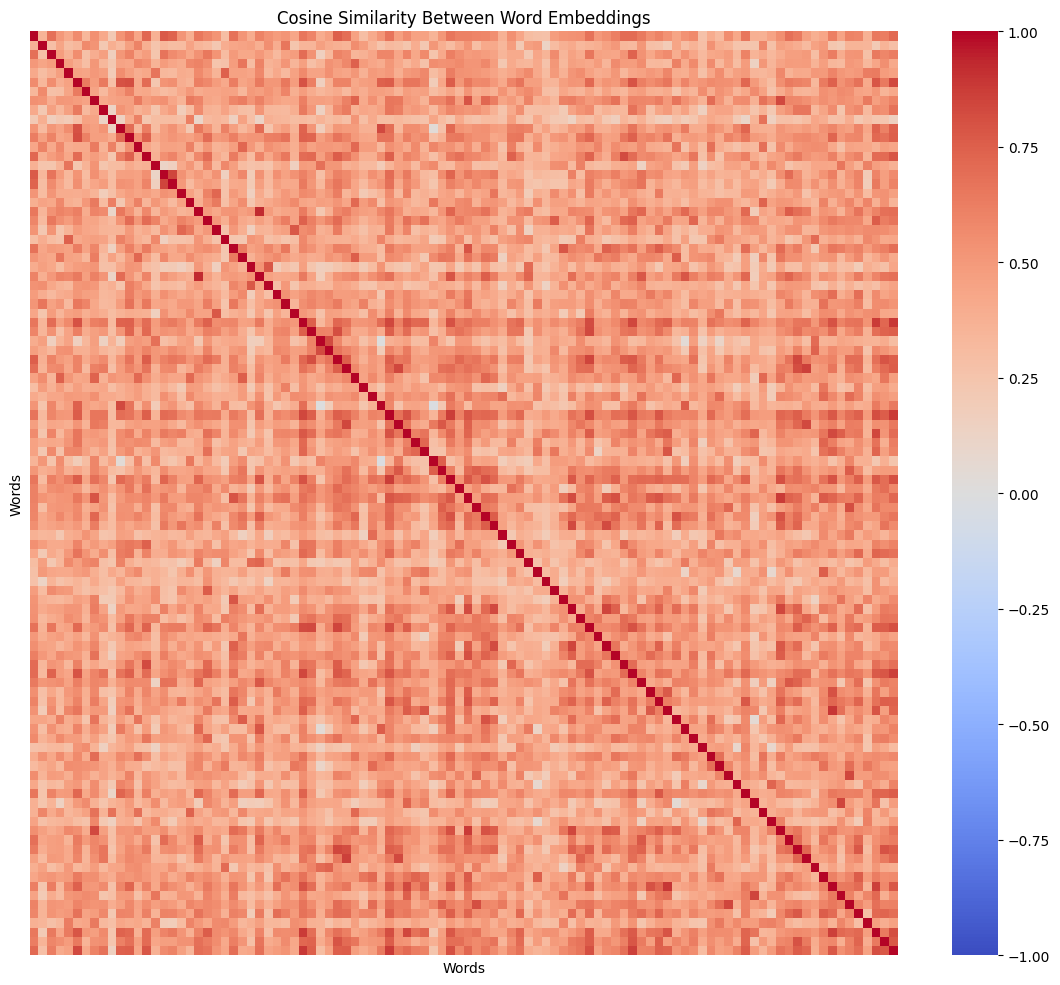

In [176]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics.pairwise import cosine_similarity

# Get all words in the Word2Vec vocabulary
#words = model.wv.index_to_key
words = model.wv.index_to_key[:100]

# Get their corresponding vectors
word_vectors = model.wv[words]

# Calculate pairwise cosine similarities
similarity_matrix = cosine_similarity(word_vectors)

# Create a DataFrame for easier inspection
similarity_df = pd.DataFrame(
    similarity_matrix,
    index=words,
    columns=words
)

# Plot heatmap
plt.figure(figsize=(14, 12))

sns.heatmap(
    similarity_df,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title("Cosine Similarity Between Word Embeddings")
plt.xlabel("Words")
plt.ylabel("Words")
plt.show()

## Character embeddings

Group dialogue by version and character


In [177]:
character_dialogues = (
    df.groupby(["version", "character"], sort=False)["dialog"]
    .apply(list)
    .to_dict()
)

In [178]:
# Group the already-tokenized dialogue by character
character_tokens = {}

for key, group in df.groupby(
    ["version", "character"],
    sort=False
):

    # Flatten the token lists into one list
    tokens = [
        token
        for dialogue_tokens in group["tokens"]
        for token in dialogue_tokens
    ]

    character_tokens[key] = tokens

In [179]:
character_embeddings = {}

for key, tokens in character_tokens.items():

    # Only keep words that exist in the Word2Vec vocabulary
    known_tokens = [
        token for token in tokens
        if token in model.wv
    ]

    if len(known_tokens) == 0:
        continue

    # Retrieve the vector for every token
    vectors = model.wv[known_tokens]

    # Calculate the average vector
    character_embedding = np.mean(vectors, axis=0)

    character_embeddings[key] = character_embedding

Embedding for character Harry Potter

In [180]:
character_embeddings[
    ("book", "Harry Potter")
]

array([ 0.11334831,  0.09539705, -0.00650912,  0.13682024, -0.08814226,
        0.10919677,  0.00173876,  0.31682906, -0.3624069 , -0.09299696,
       -0.34017956,  0.20080794,  0.0188702 ,  0.21238917, -0.13938111,
       -0.0681131 , -0.03847798, -0.37840787, -0.06862214,  0.11798743,
       -0.06683535,  0.198303  ,  0.16422522,  0.08208656,  0.18070646,
        0.06644709, -0.12252909,  0.15287147, -0.13587096, -0.19160248,
        0.04181015,  0.05314114, -0.09851982,  0.04839057,  0.06780496,
       -0.05198219,  0.17717229, -0.2993399 ,  0.02186691,  0.19267486,
        0.01284408, -0.03021595,  0.23218971, -0.19767675, -0.0250247 ,
       -0.06821661,  0.14075458,  0.13693582,  0.31140167, -0.18799594,
       -0.0492266 , -0.32200232, -0.02636587,  0.07537843,  0.31083366,
       -0.1560023 ,  0.04344515,  0.02781989, -0.18595108,  0.14473273,
       -0.02740015,  0.01728237, -0.15058231,  0.22937752,  0.18820485,
        0.10642242,  0.08763913, -0.20271145, -0.07584549, -0.09

This is useful because you might find that a character has only 60% of their dialogue represented in your model's vocabulary. Their resulting embedding would then be based on incomplete information.

Also, characters with very little dialogue will have less reliable embeddings.

In [181]:
character_coverage = {}

for key, tokens in character_tokens.items():

    known_tokens = [
        token for token in tokens
        if token in model.wv
    ]

    character_coverage[key] = {
        "total_tokens": len(tokens),
        "known_tokens": len(known_tokens),
        "coverage": len(known_tokens) / len(tokens)
    }

coverage_df = pd.DataFrame.from_dict(
    character_coverage,
    orient="index"
)

print(coverage_df.sort_values("coverage"))

                           total_tokens  known_tokens  coverage
film Nigel Wolpert                    5             4  0.800000
book Nearly Headless Nick           126           106  0.841270
     Pansy Parkinson                 26            23  0.884615
     Fleur Delacour                 295           265  0.898305
film Lily Potter                     10             9  0.900000
...                                 ...           ...       ...
book Padma Patil                     36            36  1.000000
film Old man                          2             2  1.000000
     Filius Flitwick                  2             2  1.000000
     Viktor Krum                     16            16  1.000000
book Dennis Creevey                  13            13  1.000000

[103 rows x 3 columns]


Character embedding similarity

Get the 30 characters with most dialogue

In [182]:
character_embeddings = {character: embedding for character, embedding in list(character_embeddings.items())[:10]}

In [183]:
print(f"Number of characters: {len(character_embeddings.keys())}")

Number of characters: 10


In [184]:
import numpy as np
import pandas as pd

from sklearn.metrics.pairwise import cosine_similarity

# Get character identifiers
character_keys = list(character_embeddings.keys())
print(f"Number of characters: {len(character_keys)}")

# Create readable labels
character_labels = [
    f"{character} ({version})"
    for version, character in character_keys
]

# Stack all character embeddings into one matrix
X = np.vstack([
    character_embeddings[key]
    for key in character_keys
])

print("Embedding matrix shape:", X.shape)

Number of characters: 10
Embedding matrix shape: (10, 100)


In [185]:
# Calculate pairwise cosine similarities
similarity_matrix = cosine_similarity(X)

# Convert into a labelled DataFrame
similarity_df = pd.DataFrame(
    similarity_matrix,
    index=character_labels,
    columns=character_labels
)

print(similarity_df)

                        Unknown (book)  Ted Tonks (book)  \
Unknown (book)                1.000000          0.998107   
Ted Tonks (book)              0.998107          1.000000   
Peter Pettigrew (book)        0.994705          0.993897   
Petunia Dursley (book)        0.965102          0.967090   
Vernon Dursley (book)         0.991347          0.987058   
Harry Potter (book)           0.996946          0.996374   
George Weasley (book)         0.993302          0.991995   
Fred Weasley (book)           0.995870          0.995438   
Ron Weasley (book)            0.995444          0.995127   
Dudley Dursley (book)         0.941745          0.943187   

                        Peter Pettigrew (book)  Petunia Dursley (book)  \
Unknown (book)                        0.994705                0.965102   
Ted Tonks (book)                      0.993897                0.967090   
Peter Pettigrew (book)                1.000000                0.950978   
Petunia Dursley (book)                0.950

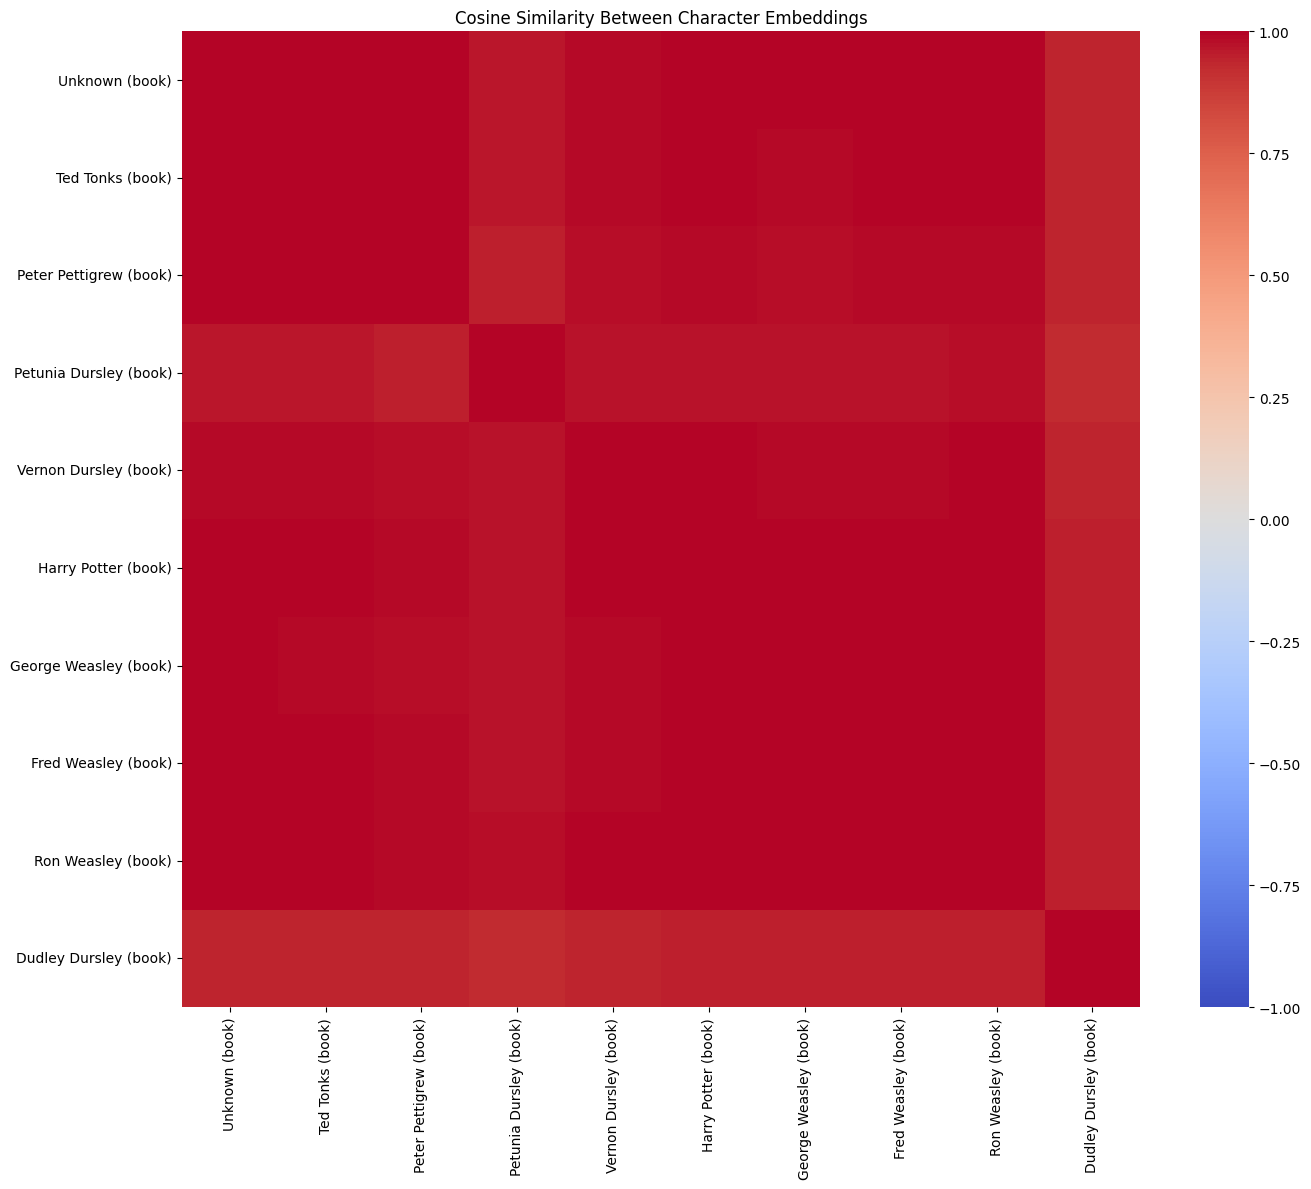

In [186]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 12))

sns.heatmap(
    similarity_df,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False,
    fmt=".2f"
)

plt.title("Cosine Similarity Between Character Embeddings")
plt.tight_layout()
plt.show()

Projection

In [187]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt

# Normalize character embeddings
X_normalized = normalize(X, norm="l2")

# Reduce from 100 dimensions to 2 dimensions
pca = PCA(n_components=2)

X_2d = pca.fit_transform(X_normalized)

print("Original shape:", X.shape)
print("Projected shape:", X_2d.shape)

print(
    "Explained variance:",
    pca.explained_variance_ratio_
)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

Original shape: (10, 100)
Projected shape: (10, 2)
Explained variance: [0.49101165 0.31029335]
Total explained variance: 0.801305


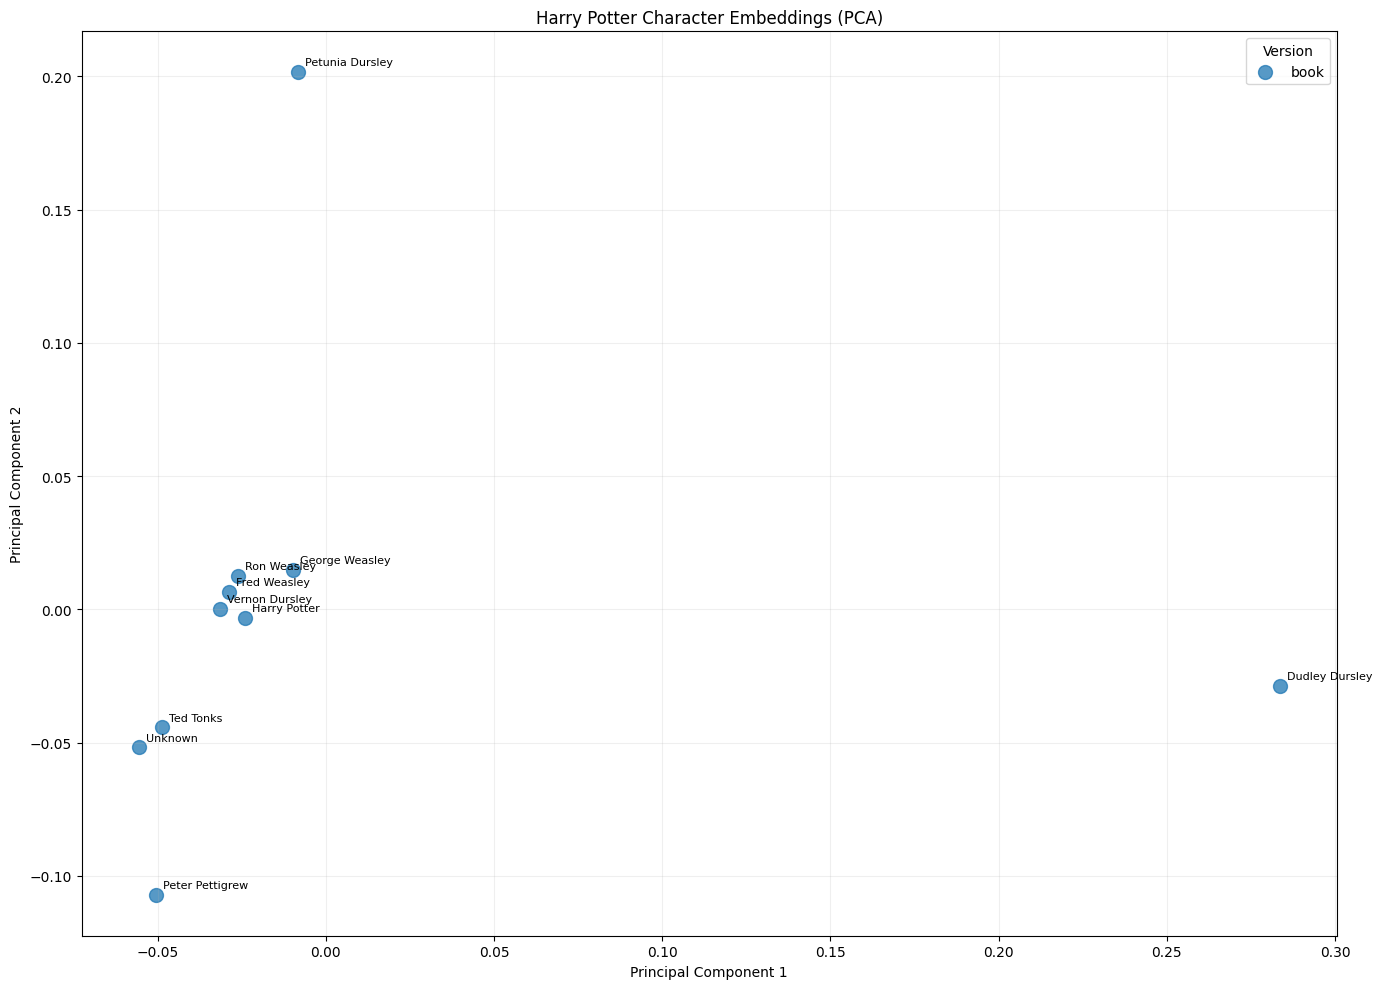

In [188]:
# Create a DataFrame with the 2D coordinates
plot_df = pd.DataFrame({
    "character": [key[1] for key in character_keys],
    "version": [key[0] for key in character_keys],
    "PC1": X_2d[:, 0],
    "PC2": X_2d[:, 1]
})

# Plot
plt.figure(figsize=(14, 10))

for version in plot_df["version"].unique():

    subset = plot_df[plot_df["version"] == version]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=version,
        s=100,
        alpha=0.75
    )

    # Add character labels
    for _, row in subset.iterrows():
        plt.annotate(
            row["character"],
            (row["PC1"], row["PC2"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("Harry Potter Character Embeddings (PCA)")
plt.legend(title="Version")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [189]:
# Main and secondary villains in the original Harry Potter stories

villains = [
    # Main villains
    "Lord Voldemort",
    "Bellatrix Lestrange",
    "Peter Pettigrew",
    "Barty Crouch Jr.",
    "Quirinus Quirrell",
    "Dolores Umbridge",

    # Death Eaters and other antagonists
    "Lucius Malfoy",
    "Fenrir Greyback",
    "Antonin Dolohov",
    "Augustus Rookwood",
    "Walden Macnair",
    "Amycus Carrow",
    "Alecto Carrow",
    "Rodolphus Lestrange",
    "Rabastan Lestrange",
    "Igor Karkaroff",
    "Corban Yaxley",
    "Thorfinn Rowle",
    "Travers",
    "Avery",
    "Mulciber",
    "Gibbon",
    "Jugson",
    "Selwyn",
    "Vincent Crabbe",
    "Gregory Goyle",
]

# Characters whose classification is more debatable
ambiguous_antagonists = [
    "Draco Malfoy",
    "Pansy Parkinson",
]

# Wider Wizarding World villain, outside the main Harry Potter story
wider_universe_villains = [
    "Gellert Grindelwald",
]

In [190]:
villain_aliases = {
    "Tom Riddle": "Lord Voldemort",
    "Tom Marvolo Riddle": "Lord Voldemort",
    "Voldemort": "Lord Voldemort",
    "Wormtail": "Peter Pettigrew",
    "Barty Crouch Junior": "Barty Crouch Jr.",
    "Professor Quirrell": "Quirinus Quirrell",
}

In [191]:
# Count the number of tokens in each dialogue row
df["word_count"] = df["tokens"].apply(len)

# Select book data
book_df = df[df["version"] == "book"]

# Select movie data
movie_df = df[df["version"].isin(["film", "movie"])]

# Sum dialogue words for each character
book_counts = (
    book_df.groupby("character")["word_count"]
    .sum()
    .sort_values(ascending=False)
)

movie_counts = (
    movie_df.groupby("character")["word_count"]
    .sum()
    .sort_values(ascending=False)
)

# Select the 20 characters with most dialogue
top20_books = book_counts.head(20)
top20_movies = movie_counts.head(20)

print("TOP 20 BOOK CHARACTERS")
print(top20_books)

print("\nTOP 20 MOVIE CHARACTERS")
print(top20_movies)

TOP 20 BOOK CHARACTERS
character
Harry Potter          11622
Unknown                7941
Ron Weasley            7221
Hermione Granger       6667
Albus Dumbledore       3627
Alastor Moody          2068
Rubeus Hagrid          1493
Sirius Black           1448
Fred Weasley           1410
Molly Weasley          1138
Percy Weasley          1134
Bartemius Crouch        925
Severus Snape           849
George Weasley          766
Igor Karkaroff          733
Voldemort               665
Cornelius Fudge         625
Draco Malfoy            599
Ted Tonks               594
Minerva McGonagall      550
Name: word_count, dtype: int64

TOP 20 MOVIE CHARACTERS
character
Albus Dumbledore      1461
Harry Potter          1154
Alastor Moody          879
Ron Weasley            759
Hermione Granger       708
Voldemort              449
Bartemius Crouch       364
Minerva McGonagall     317
Rita Skeeter           271
Rubeus Hagrid          265
Sirius Black           233
Arthur Weasley         161
Cedric Diggory   

In [192]:
import numpy as np
import pandas as pd
import re

from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns


# Normalize names for villain matching
def normalize_name(name):
    return re.sub(
        r"[^a-z0-9]+",
        " ",
        str(name).lower()
    ).strip()


# Create a set containing all villain names and aliases
villain_names = set(normalize_name(v) for v in villains)

villain_names.update(
    normalize_name(v) for v in villain_aliases
)


def is_villain(character):
    return normalize_name(character) in villain_names


def analyze_top_characters(data, version, top_n=20):

    # 1. Count dialogue words for each character
    counts = (
        data.groupby("character")["tokens"]
        .apply(lambda dialogues: sum(len(x) for x in dialogues))
        .sort_values(ascending=False)
    )

    top_characters = counts.head(top_n)

    # 2. Generate an embedding for each character
    embeddings = {}
    coverage = {}

    for character in top_characters.index:

        # Collect all tokens from this character's dialogue
        character_dialogues = data[
            data["character"] == character
        ]["tokens"]

        tokens = [
            token
            for dialogue in character_dialogues
            for token in dialogue
        ]

        # Keep only words available in Word2Vec
        known_tokens = [
            token for token in tokens
            if token in model.wv
        ]

        if not known_tokens:
            continue

        # Retrieve word embeddings
        vectors = model.wv[known_tokens]

        # Average word embeddings
        embeddings[character] = np.mean(
            vectors,
            axis=0
        )

        coverage[character] = (
            len(known_tokens) / len(tokens)
            if tokens else 0
        )

    # 3. Create embedding matrix
    characters = list(embeddings.keys())

    X = np.vstack([
        embeddings[character]
        for character in characters
    ])

    # 4. Calculate cosine similarity
    similarity_matrix = cosine_similarity(X)

    # 5. Create labelled similarity DataFrame
    labels = [
        f"{c} [V]" if is_villain(c) else c
        for c in characters
    ]

    similarity_df = pd.DataFrame(
        similarity_matrix,
        index=labels,
        columns=labels
    )

    # 6. Create heatmap
    plt.figure(figsize=(14, 11))

    sns.heatmap(
        similarity_df,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 8},
        square=True,
        cbar_kws={"label": "Cosine similarity"}
    )

    plt.title(
        f"Character Embedding Similarity - {version.capitalize()} (Top 20)",
        fontsize=14
    )

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    # 7. Print dialogue counts and embedding coverage
    result = pd.DataFrame({
        "dialogue_words": top_characters,
        "embedding_coverage": pd.Series(coverage)
    })

    print(f"\nTop characters in {version}:")
    print(result)

    return embeddings, similarity_df, result

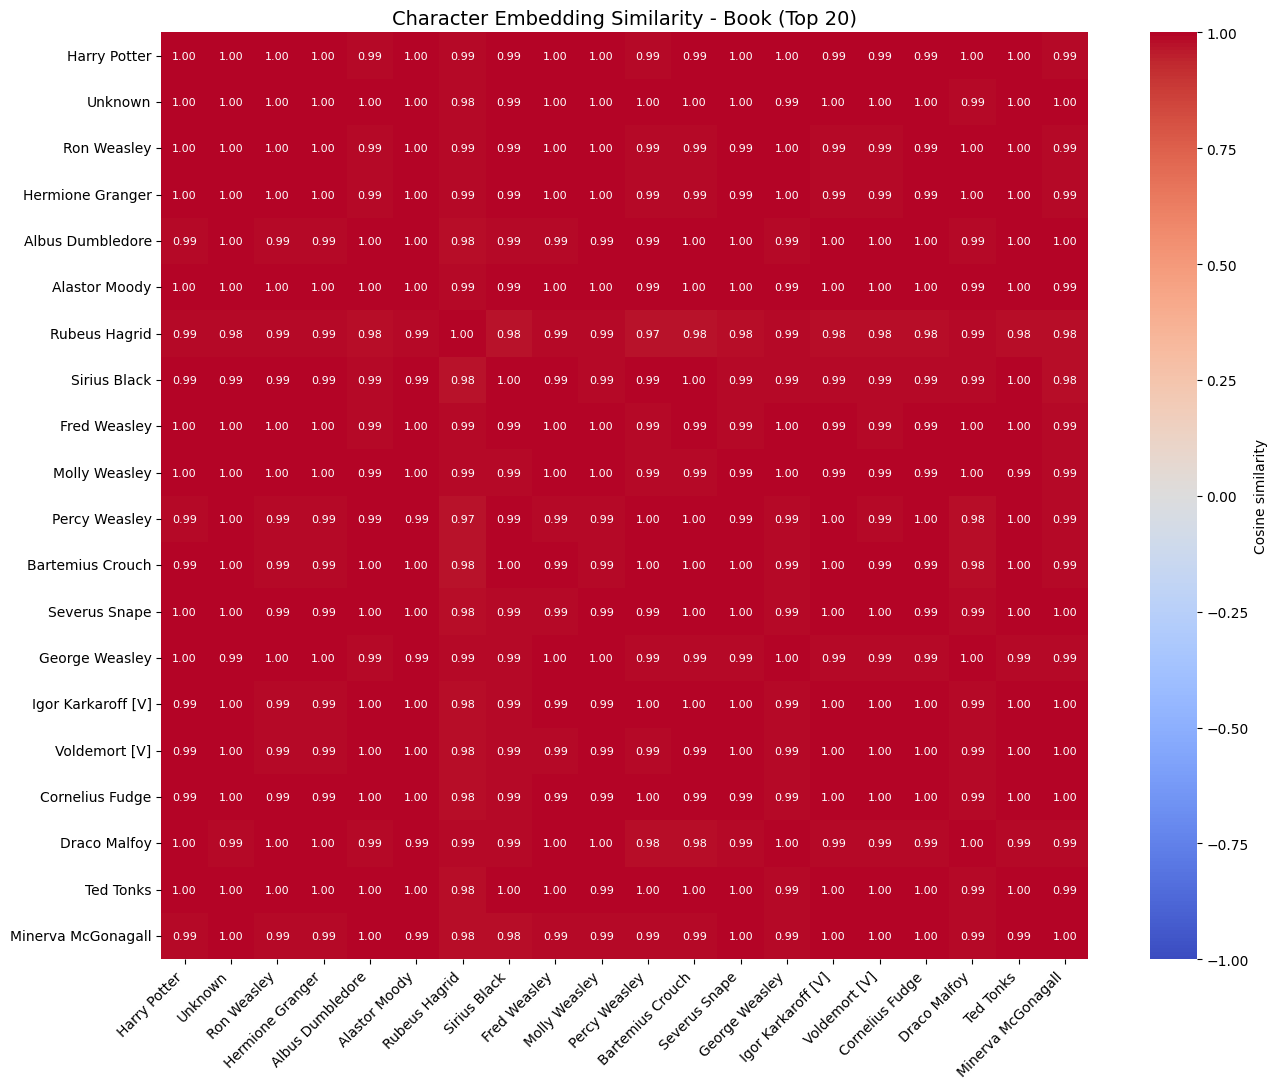


Top characters in book:
                    dialogue_words  embedding_coverage
Harry Potter                 11622            0.970057
Unknown                       7941            0.958318
Ron Weasley                   7221            0.965102
Hermione Granger              6667            0.974351
Albus Dumbledore              3627            0.958092
Alastor Moody                 2068            0.971470
Rubeus Hagrid                 1493            0.961822
Sirius Black                  1448            0.964088
Fred Weasley                  1410            0.956028
Molly Weasley                 1138            0.971002
Percy Weasley                 1134            0.925926
Bartemius Crouch               925            0.962162
Severus Snape                  849            0.963486
George Weasley                 766            0.966057
Igor Karkaroff                 733            0.941337
Voldemort                      665            0.959398
Cornelius Fudge                625      

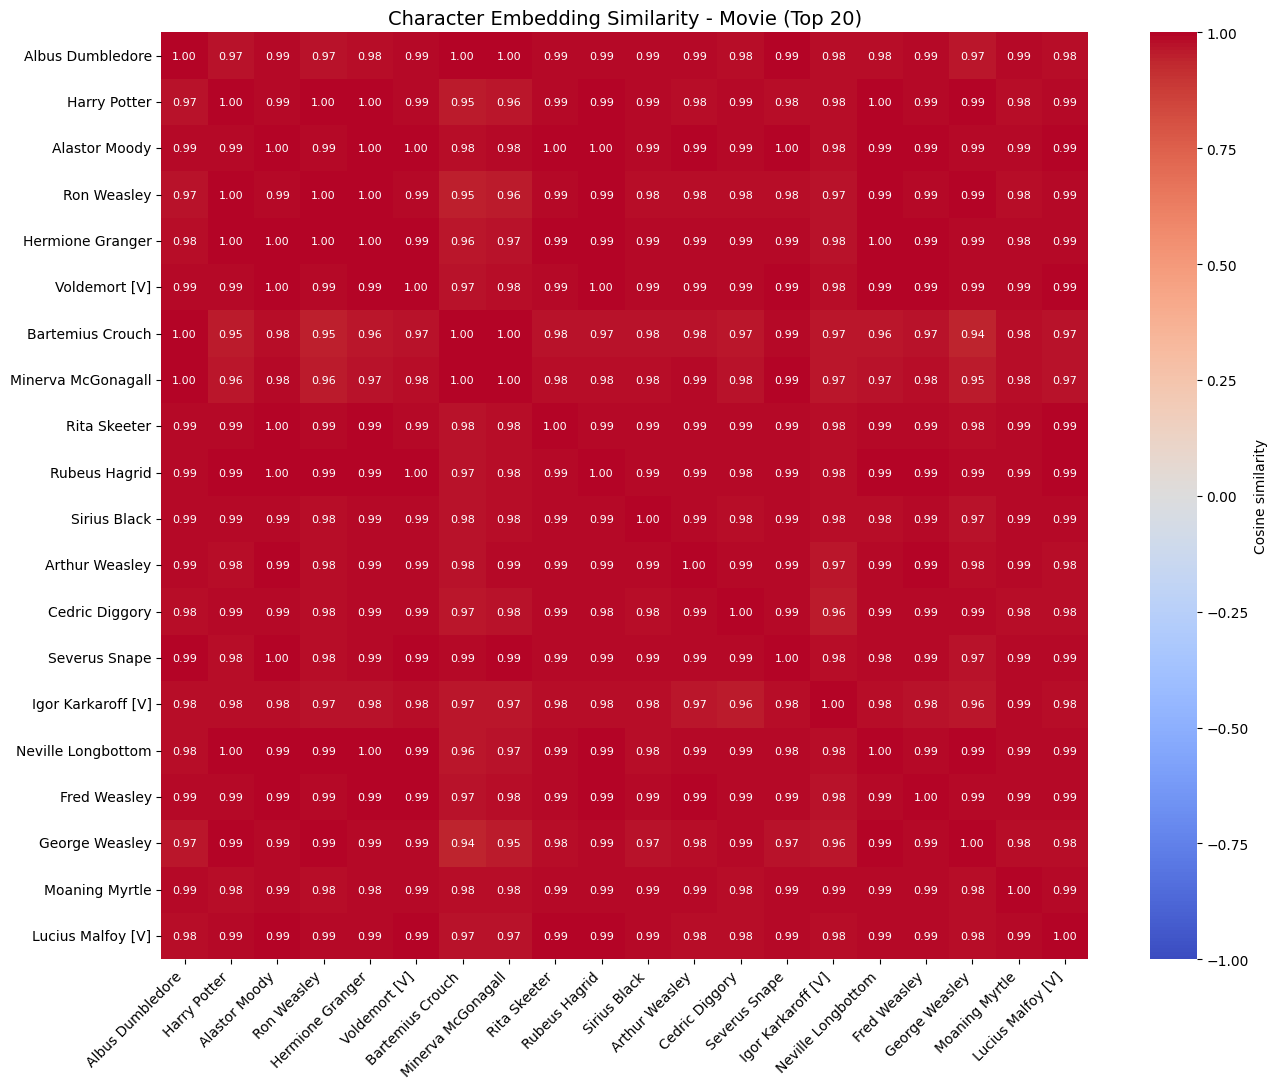


Top characters in movie:
                    dialogue_words  embedding_coverage
Albus Dumbledore              1461            0.966461
Harry Potter                  1154            0.981802
Alastor Moody                  879            0.962457
Ron Weasley                    759            0.971014
Hermione Granger               708            0.971751
Voldemort                      449            0.971047
Bartemius Crouch               364            0.953297
Minerva McGonagall             317            0.921136
Rita Skeeter                   271            0.915129
Rubeus Hagrid                  265            0.973585
Sirius Black                   233            0.965665
Arthur Weasley                 161            0.956522
Cedric Diggory                 153            0.980392
Severus Snape                  150            0.920000
Igor Karkaroff                 134            0.992537
Neville Longbottom             112            0.919643
Fred Weasley                   107     

In [193]:
# Book heatmap
book_embeddings, book_similarity, book_results = (
    analyze_top_characters(
        book_df,
        version="book",
        top_n=20
    )
)

# Movie heatmap
movie_embeddings, movie_similarity, movie_results = (
    analyze_top_characters(
        movie_df,
        version="movie",
        top_n=20
    )
)

## Stopwords removal

In [194]:
from gensim.parsing.preprocessing import STOPWORDS
from collections import Counter

# Standard English stopwords
stop_words = set(STOPWORDS)

# Keep words that might be important for character speaking style
preserve_words = {
    "i", "me", "my", "mine",
    "you", "your", "yours",
    "he", "him", "his",
    "she", "her",
    "we", "us", "our",
    "they", "them", "their",
    "not", "no", "nor", "never",
    "must", "should", "would",
    "could", "can", "will"
}

stop_words = stop_words - preserve_words

In [195]:
# Count all tokens across the entire dataset
all_tokens = [
    token
    for tokens in df["tokens"]
    for token in tokens
]

word_counts = Counter(all_tokens)

total_words = sum(word_counts.values())

# Display the 40 most frequent words
for word, count in word_counts.most_common(40):
    print(f"{word}: {count}")

you: 2357
the: 2042
i: 1955
to: 1791
s: 1286
it: 1148
a: 1109
and: 1020
t: 975
of: 957
he: 894
that: 728
in: 622
what: 598
is: 543
we: 518
they: 500
me: 456
be: 456
for: 454
harry: 453
not: 437
have: 436
was: 433
on: 384
him: 379
my: 378
your: 370
all: 369
this: 359
ve: 344
but: 340
know: 336
no: 324
are: 323
re: 316
do: 315
don: 311
with: 307
at: 291


In [196]:
# Words occurring in more than 0.5% of all tokens
very_frequent_words = {
    word
    for word, count in word_counts.items()
    if count / total_words > 0.005
}

# Retain our selected speaking-style words
very_frequent_words -= preserve_words

# Combine both exclusion lists
excluded_words = stop_words | very_frequent_words

print("Number of excluded words:", len(excluded_words))
print("Frequently excluded words:", very_frequent_words)

Number of excluded words: 314
Frequently excluded words: {'of', 've', 'the', 'what', 'that', 's', 'harry', 'but', 'and', 'all', 'this', 'know', 'to', 'for', 'was', 'in', 'have', 't', 'is', 'on', 'a', 'be', 'it'}


In [197]:
def create_character_embedding(tokens, model, excluded_words):

    # Remove stopwords and words not in Word2Vec vocabulary
    filtered_tokens = [
        token
        for token in tokens
        if token not in excluded_words
        and token in model.wv
    ]

    if len(filtered_tokens) == 0:
        return None

    # Retrieve word vectors
    vectors = model.wv[filtered_tokens]

    # Average the vectors
    embedding = np.mean(vectors, axis=0)

    return embedding

In [198]:
def analyze_top_characters(data, version, top_n=20):

    # Count dialogue words for each character
    counts = (
        data.groupby("character")["tokens"]
        .apply(lambda dialogues: sum(len(x) for x in dialogues))
        .sort_values(ascending=False)
    )

    top_characters = counts.head(top_n)

    embeddings = {}
    coverage = {}

    for character in top_characters.index:

        character_dialogues = data[
            data["character"] == character
        ]["tokens"]

        tokens = [
            token
            for dialogue in character_dialogues
            for token in dialogue
        ]

        # Filter out stopwords and frequent words
        filtered_tokens = [
            token for token in tokens
            if token not in excluded_words
            and token in model.wv
        ]

        if not filtered_tokens:
            continue

        # Calculate character embedding
        vectors = model.wv[filtered_tokens]

        embeddings[character] = np.mean(
            vectors,
            axis=0
        )

        # Calculate how many tokens were retained
        coverage[character] = (
            len(filtered_tokens) / len(tokens)
        )

    # Build embedding matrix
    characters = list(embeddings.keys())

    X = np.vstack([
        embeddings[c] for c in characters
    ])

    # Calculate cosine similarities
    similarity_matrix = cosine_similarity(X)

    labels = [
        f"{c} [V]" if is_villain(c) else c
        for c in characters
    ]

    similarity_df = pd.DataFrame(
        similarity_matrix,
        index=labels,
        columns=labels
    )

    # Plot heatmap
    plt.figure(figsize=(12, 10))

    sns.heatmap(
        similarity_df,
        cmap="coolwarm",
        vmin=0,
        vmax=1,
        annot=True,
        fmt=".2f",
        square=True
    )

    plt.title(
        f"Character Similarity - {version.capitalize()} (Top 20)"
    )

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    # Show coverage
    coverage_df = pd.DataFrame({
        "dialogue_words": top_characters,
        "retained_tokens": pd.Series({
            c: sum(
                len(t)
                for t in data[data["character"] == c]["tokens"]
            )
            for c in characters
        }),
        "coverage": pd.Series(coverage)
    })

    print(coverage_df)

    return embeddings, similarity_df

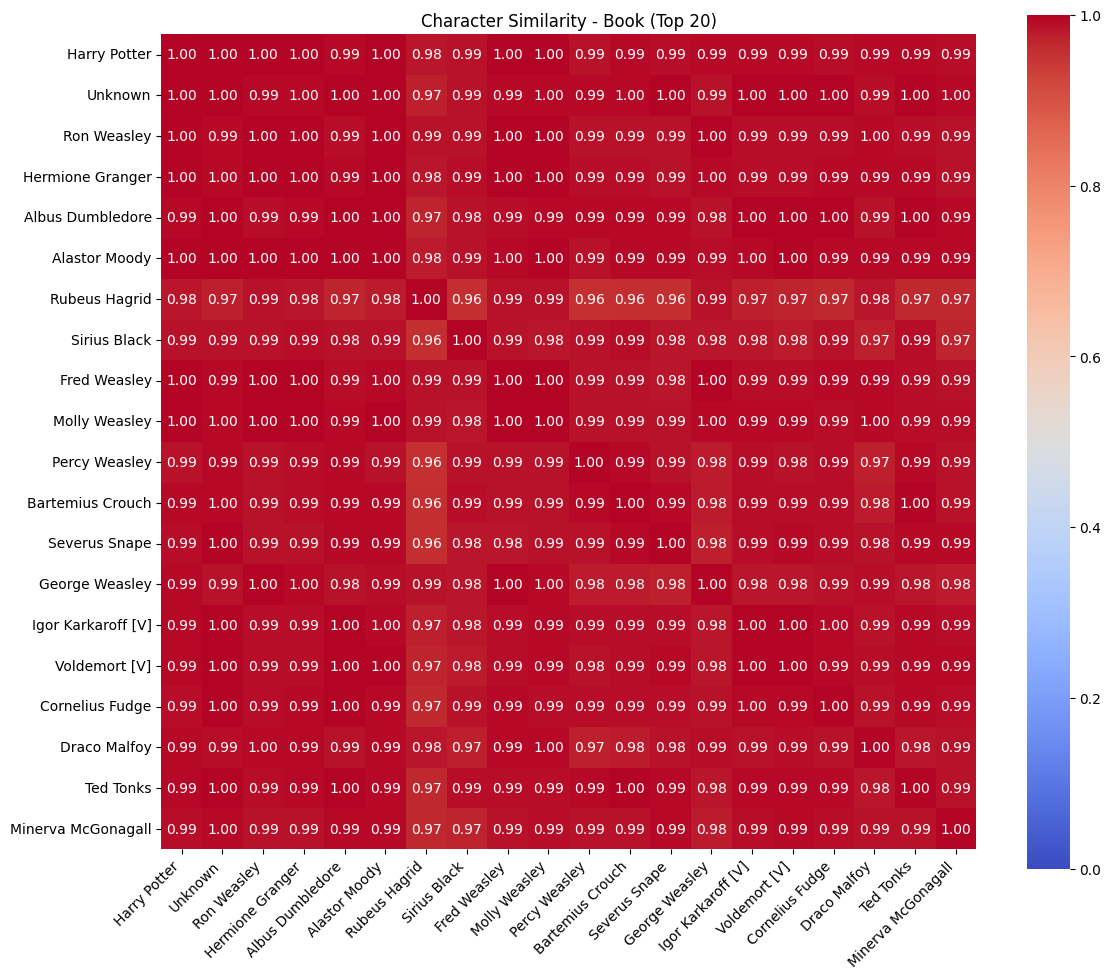

                    dialogue_words  retained_tokens  coverage
Harry Potter                 11622            11622  0.514541
Unknown                       7941             7941  0.516434
Ron Weasley                   7221             7221  0.502700
Hermione Granger              6667             6667  0.490925
Albus Dumbledore              3627             3627  0.506479
Alastor Moody                 2068             2068  0.515474
Rubeus Hagrid                 1493             1493  0.585399
Sirius Black                  1448             1448  0.479282
Fred Weasley                  1410             1410  0.502128
Molly Weasley                 1138             1138  0.512302
Percy Weasley                 1134             1134  0.473545
Bartemius Crouch               925              925  0.544865
Severus Snape                  849              849  0.521790
George Weasley                 766              766  0.494778
Igor Karkaroff                 733              733  0.502046
Voldemor

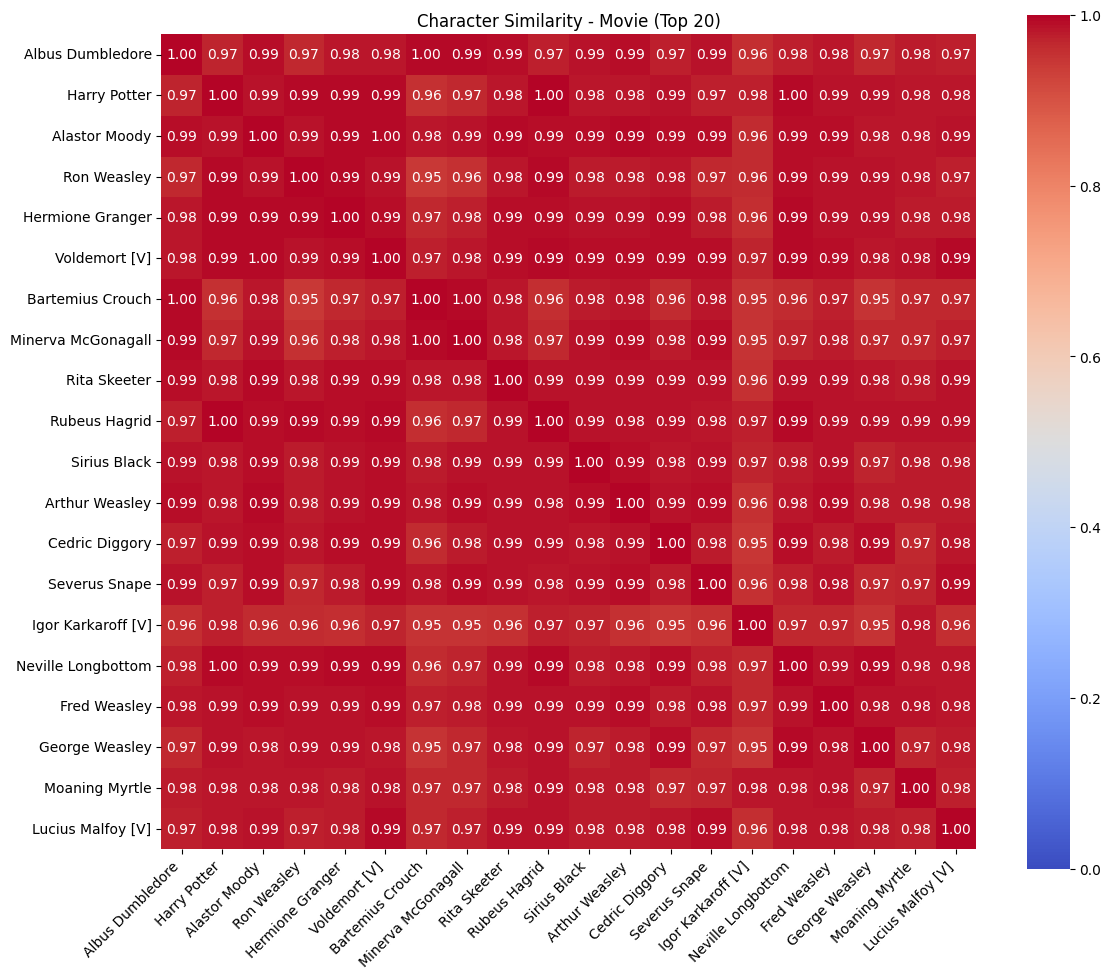

                    dialogue_words  retained_tokens  coverage
Albus Dumbledore              1461             1461  0.491444
Harry Potter                  1154             1154  0.513865
Alastor Moody                  879              879  0.494881
Ron Weasley                    759              759  0.515152
Hermione Granger               708              708  0.475989
Voldemort                      449              449  0.572383
Bartemius Crouch               364              364  0.497253
Minerva McGonagall             317              317  0.451104
Rita Skeeter                   271              271  0.476015
Rubeus Hagrid                  265              265  0.513208
Sirius Black                   233              233  0.433476
Arthur Weasley                 161              161  0.490683
Cedric Diggory                 153              153  0.503268
Severus Snape                  150              150  0.480000
Igor Karkaroff                 134              134  0.529851
Neville 

In [199]:
book_embeddings, book_similarity = analyze_top_characters(
    book_df, "book"
)

movie_embeddings, movie_similarity = analyze_top_characters(
    movie_df, "movie"
)

Word weights

In [200]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import pandas as pd

from gensim.parsing.preprocessing import STOPWORDS

# Keep potentially interesting words for speaking style
preserve_words = {
    "i", "me", "my", "mine",
    "you", "your", "yours",
    "he", "him", "his",
    "she", "her",
    "we", "us", "our",
    "they", "them", "their",
    "not", "no", "never",
    "must", "should", "would",
    "could", "can", "will"
}

stop_words = set(STOPWORDS) - preserve_words

# Normalize version names
df["version"] = df["version"].str.lower().replace({
    "movie": "film"
})

# Group all dialogue by character and version
character_docs = (
    df.groupby(["version", "character"])["tokens"]
    .apply(lambda rows: [
        word
        for dialogue in rows
        for word in dialogue
        if word not in stop_words
    ])
    .reset_index(name="tokens")
)

# Keep original dialogue length for later analysis
character_docs["word_count"] = (
    character_docs["tokens"].apply(len)
)

# Convert token lists into documents
documents = character_docs["tokens"].apply(" ".join)

# Train TF-IDF weighting model
tfidf_vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    preprocessor=None,
    token_pattern=None,
    lowercase=False,
    sublinear_tf=True,
    use_idf=True,
    smooth_idf=True,
    norm=None,
    max_df=0.85
)

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (103, 4789)


In [201]:
# Get all words in the TF-IDF vocabulary
feature_names = np.array(
    tfidf_vectorizer.get_feature_names_out()
)

weighted_character_embeddings = {}

for i, row in character_docs.iterrows():

    key = (row["version"], row["character"])

    # Retrieve this character's TF-IDF row
    tfidf_row = tfidf_matrix.getrow(i)

    # Get words and corresponding weights
    word_indices = tfidf_row.indices
    weights = tfidf_row.data

    words = feature_names[word_indices]

    # Keep only words present in Word2Vec
    valid = np.array([
        word in model.wv
        for word in words
    ])

    words = words[valid]
    weights = weights[valid]

    if len(words) == 0 or weights.sum() == 0:
        continue

    # Retrieve Word2Vec embeddings
    vectors = model.wv[words]

    # Calculate weighted average
    character_embedding = np.average(
        vectors,
        axis=0,
        weights=weights
    )

    weighted_character_embeddings[key] = character_embedding

print(
    "Number of weighted character embeddings:",
    len(weighted_character_embeddings)
)

Number of weighted character embeddings: 103


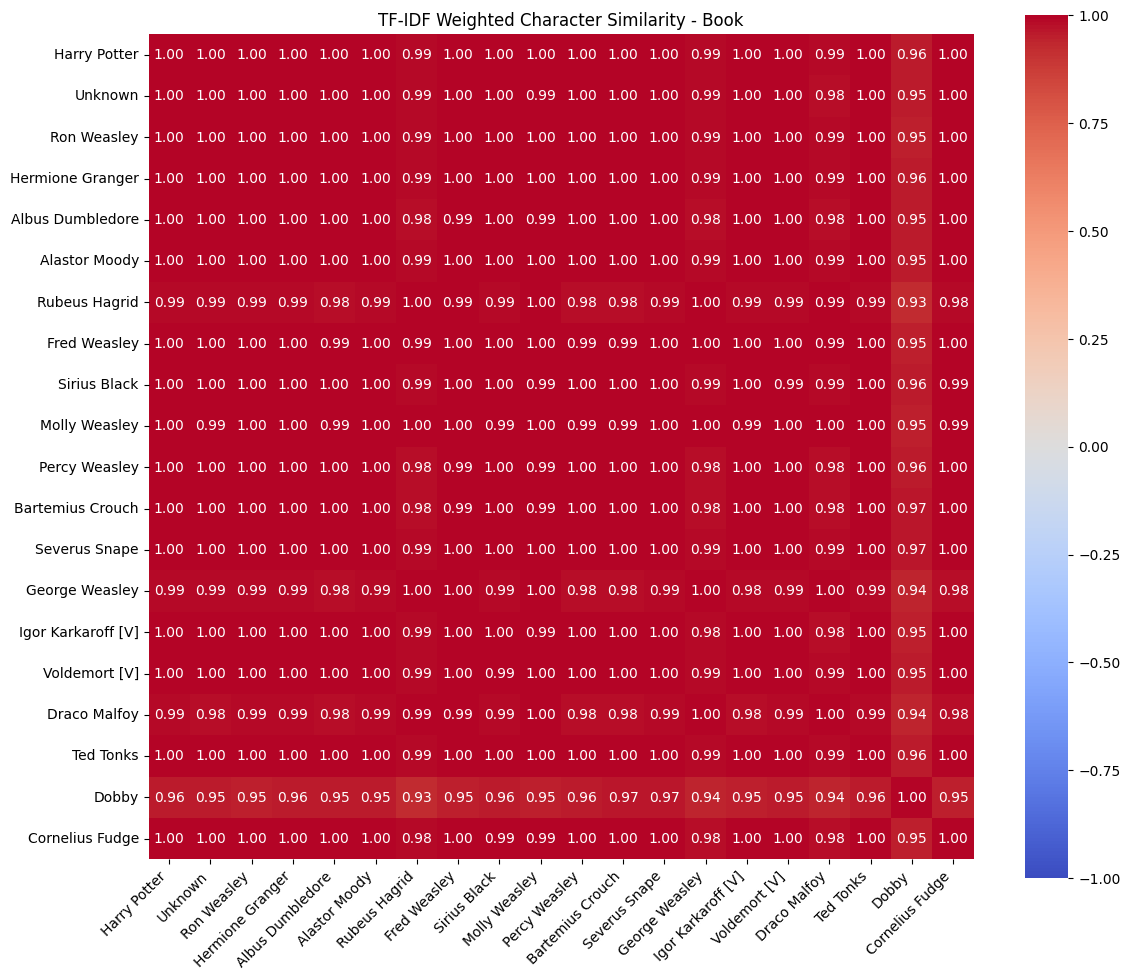

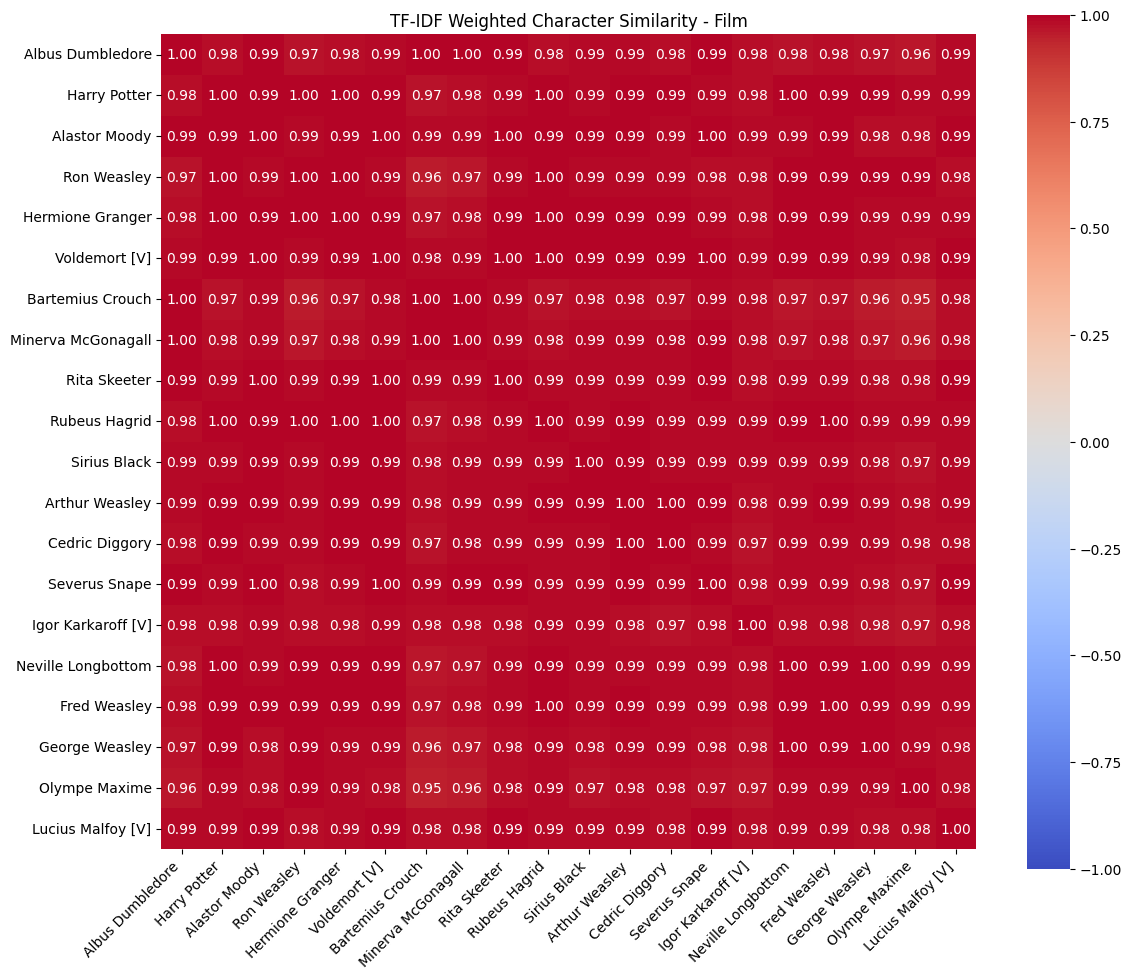

In [202]:
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns


def plot_weighted_similarity(version, top_n=20):

    # Select characters from the requested version
    subset = character_docs[
        character_docs["version"] == version
    ]

    # Get the top characters by dialogue word count
    top_characters = (
        subset.nlargest(top_n, "word_count")["character"]
        .tolist()
    )

    # Retrieve their weighted embeddings
    characters = [
        c for c in top_characters
        if (version, c) in weighted_character_embeddings
    ]

    X = np.vstack([
        weighted_character_embeddings[(version, c)]
        for c in characters
    ])

    # Calculate cosine similarity
    similarity = cosine_similarity(X)

    # Add villain labels
    labels = [
        f"{c} [V]" if is_villain(c) else c
        for c in characters
    ]

    similarity_df = pd.DataFrame(
        similarity,
        index=labels,
        columns=labels
    )

    # Plot heatmap
    plt.figure(figsize=(12, 10))

    sns.heatmap(
        similarity_df,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt=".2f",
        square=True
    )

    plt.title(
        f"TF-IDF Weighted Character Similarity - {version.capitalize()}"
    )

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    return similarity_df


# Book heatmap
book_weighted_similarity = plot_weighted_similarity("book")

# Movie heatmap
movie_weighted_similarity = plot_weighted_similarity("film")

In [203]:
def most_important_words(version, character, top_n=15):

    # Find the character's document
    idx = character_docs.index[
        (character_docs["version"] == version) &
        (character_docs["character"] == character)
    ][0]

    # Retrieve TF-IDF scores
    row = tfidf_matrix.getrow(idx)

    words = feature_names[row.indices]
    weights = row.data

    result = pd.DataFrame({
        "word": words,
        "tfidf_weight": weights
    })

    return result.sort_values(
        "tfidf_weight",
        ascending=False
    ).head(top_n)


print(most_important_words("book", "Draco Malfoy"))

         word  tfidf_weight
43   mudblood      9.539827
149   weasley      8.650196
18      train      7.209584
29     losing      7.209584
141    potter      7.196845
58    picture      6.523072
119    trying      6.307030
132   granger      6.307030
54       hang      6.035984
136      they      5.728381
68   thinking      5.658169
138  attacked      5.658169
39      enter      5.496795
110     weren      5.349472
61       hasn      5.213948
